# A/B Testing for Website 

# Problem Statement :
An e-commerce startup wants to know if a new checkout funnels(B) outperforms the old one(A)

Steps:
1. Simulate click

# Step 1: Simulate Data for A/B testing

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt 
from statsmodels.stats.proportion import proportions_ztest

In [2]:
np.random.seed(42)

In [3]:
# Assuming there are 10000  vistors in each group
n_A_vistors = 10000 
n_B_vistors = 10000

# p_A and B is true conversion rate for A and B
# For example, let's say the true conversion rate for A is 10% and for B is 12%
p_A = 0.10 
p_B = 0.12

In [4]:
# Let there is two method of purchase true or false (Binomial Data)
sucess_A = np.random.binomial(n_A_vistors, p_A)
sucess_B = np.random.binomial(n_B_vistors, p_B)
print(f"Sucess A: {sucess_A}, Sucess B: {sucess_B}")

Sucess A: 973, Sucess B: 1134


# Steps 2: Calculate conversion rates & 95% Confincdence intervals

In [5]:
'''Step 2 -> conversion rate and confidence intervals with 95% '''
def proportion_confidence_interval(sucess, n, alpha=0.05):
    """
    Calculate the confidence interval for a proportion.
    
    Parameters:
    - success: Number of successes
    - n: Total number of trials/visitors
    - alpha: Significance level / error (default is 0.05 for 95% CI)
    
    Returns:
    - (lower_bound, upper_bound): Confidence interval for the proportion
    """
    p_hat = sucess / n
    z = stats.norm.ppf(1 - alpha / 2)  # Z-score for the given alpha
    se = np.sqrt(p_hat * (1 - p_hat) / n)  # Standard error
    lower_bound = p_hat - z * se
    upper_bound = p_hat + z * se
    return p_hat,lower_bound, upper_bound

In [6]:
# CR -> Conv
p_A_hat, ci_lower_A, ci_upper_A = proportion_confidence_interval(sucess_A, n_A_vistors)
print(f"Conversion Rate A: {p_A_hat:.4f}, 95% CI: ({ci_lower_A:.4f}, {ci_upper_A:.4f})")

Conversion Rate A: 0.0973, 95% CI: (0.0915, 0.1031)


In [7]:
p_B_hat, ci_lower_B, ci_upper_B = proportion_confidence_interval(sucess_B, n_B_vistors)
print(f"Conversion Rate A: {p_B_hat:.4f}, 95% CI: ({ci_lower_B:.4f}, {ci_upper_B:.4f})")

Conversion Rate A: 0.1134, 95% CI: (0.1072, 0.1196)


In [8]:
print(p_B_hat)
print(ci_lower_B)
print(ci_upper_B)

0.1134
0.1071853241430106
0.1196146758569894


In [9]:
# Calculate conversion rates and confidence intervals
results = pd.DataFrame({
    'Variant': ['A', 'B'],
    'Visitors': [n_A_vistors, n_B_vistors],
    'Conversion Rate': [sucess_A, sucess_B],
    'Conversion Rate (p_hat)': [p_A_hat, p_B_hat],
    'CI Lower Bound': [ci_lower_A, ci_lower_B],
    'CI Upper Bound': [ci_upper_A, ci_upper_B]
    
})
print(results)

  Variant  Visitors  Conversion Rate  Conversion Rate (p_hat)  CI Lower Bound  \
0       A     10000              973                   0.0973        0.091491   
1       B     10000             1134                   0.1134        0.107185   

   CI Upper Bound  
0        0.103109  
1        0.119615  


# Step 3: Plot conversion rate with error bars

In [10]:
# List all columns
print(list(results.columns))

['Variant', 'Visitors', 'Conversion Rate', 'Conversion Rate (p_hat)', 'CI Lower Bound', 'CI Upper Bound']


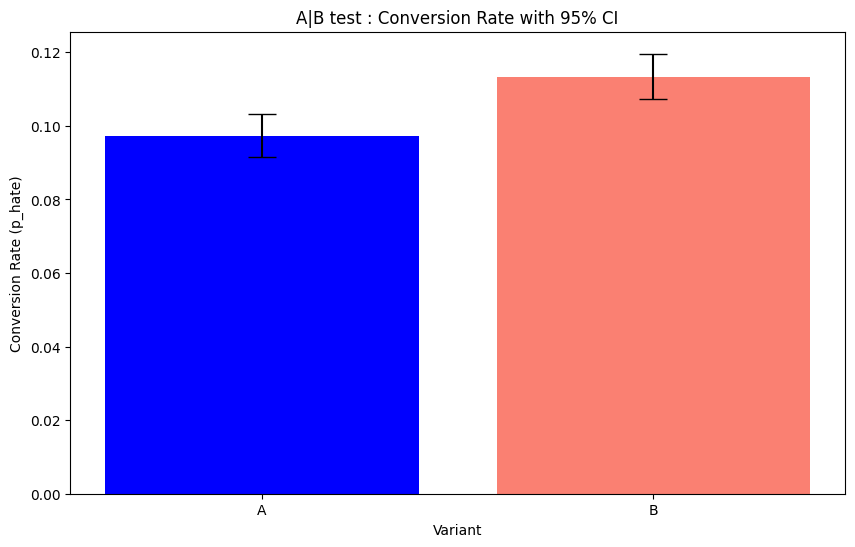

In [11]:
# Ploting converison rate with error bars
plt.figure(figsize=(10, 6))
plt.bar(
    x = results['Variant'],
    height = results['Conversion Rate (p_hat)'],
    yerr=[
        results['Conversion Rate (p_hat)'] - results['CI Lower Bound'],
        results['CI Upper Bound'] - results['Conversion Rate (p_hat)']
    ],
    capsize=10,
    color=['blue', 'salmon']
)

plt.xlabel('Variant')
plt.ylabel('Conversion Rate (p_hate)')
plt.title("A|B test : Conversion Rate with 95% CI")
plt.show()

# Step 4: 2_proportion_z-test

It is comparestion two groups (A & B) to see the differnce b/w their conversion rate:
    1. Real(Statistically signinficant)
    2. or just random chance

In [12]:
#  H0 : #  p_A <= p_B
#  H1 : #  p_A > p_B

count = np.array([sucess_B, sucess_A])  # Number of purchases
nobs = np.array([n_B_vistors, n_A_vistors])     # number of trials/vistors in each group

In [13]:
print(count)
print(nobs)

[1134  973]
[10000 10000]


In [14]:
z_stat, p_value = proportions_ztest(count, nobs, alternative='larger')
print(f"z_stat:{z_stat:.4f}")
print(f"p_value: {p_value:.4f}")

z_stat:3.7082
p_value: 0.0001


In [15]:
print(f"z_stat  : {z_stat:.3f}")
print(f"p_value : {p_value:.10f}")
if p_value < 0.05:
    print("Reject H0 : Variant B has a significantly higher conversion rate than Variant A")
else:
    print("Fail to reject H0 : No significant difference between Variant A and B")    

z_stat  : 3.708
p_value : 0.0001043552
Reject H0 : Variant B has a significantly higher conversion rate than Variant A


# Step 5: Real-Time monitoring & Sequential testing 

In [16]:
import numpy as np # as-> alias
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest
import time
from IPython.display import clear_output


In [17]:
# Real-time monitoring
true_p_A = 0.10     # True conversion rate for A
true_p_B = 0.12     # True conversion rate for B
batch_size = 100    # Number of visitors per batch
n_batches = 60      # Number of batches to simulate

# Initialize counters
n_A_vistis = 0      # Number of visitors for variant A initially 0
n_B_vistis = 0      # Number of visitors for variant B initially 0
n_sucess_A = 0      # Number of successful purchases for variant A initially 0
n_sucess_B = 0      # Number of successful purchases for variant B initially 0

batches = []  # Store batch results for plotting
p_values = []  # Store p-values for monitoring
lifts = []  # Store differebce b/t conversion of B and A

Batch60/60
Varient A: 6000 visits, 574 Buy, CR: 0.0957
Varient B: 6000 visits, 714 Buy, CR: 0.1190
Observed Lift: 2.333%
z-stat: 412.882%, p-value: 0.0018%
Significant lift


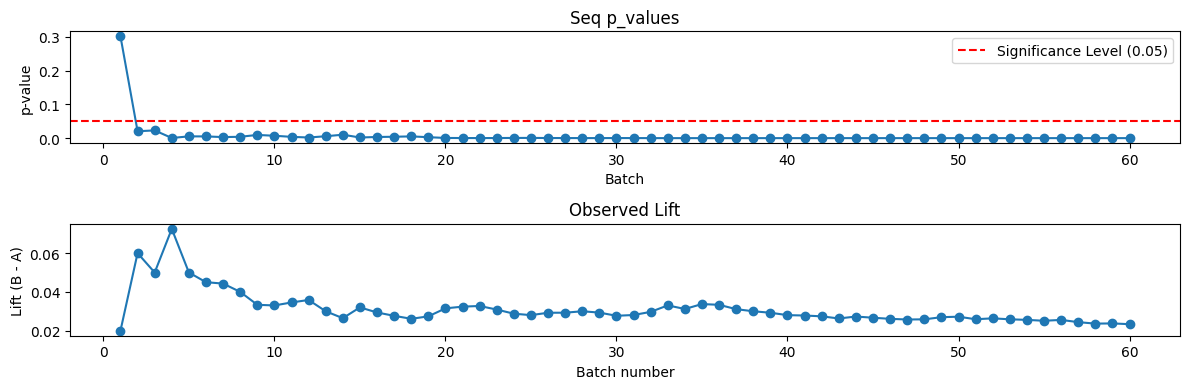

In [18]:
# Iteration 
for batch in range(1, n_batches + 1):  #n_batches = 60

    # Simulate one batch of vistors
    new_A = np.random.binomial(batch_size, true_p_A)
    new_B = np.random.binomial(batch_size, true_p_B)

    # Update total visitors and successes
    n_A_vistis += batch_size
    n_B_vistis += batch_size
    n_sucess_A += new_A
    n_sucess_B += new_B

    # Calculate current conversion rates and confidence intervals
    cr_A = n_sucess_A / n_A_vistis
    cr_B = n_sucess_B / n_B_vistis
    lift = cr_B - cr_A

    # 2=proportion z-test
    count = np.array([n_sucess_B, n_sucess_A])
    nobs = np.array([n_B_vistis, n_A_vistis])  # number of trials/vistors in each group
    z_stat, p_value = proportions_ztest(count, nobs, alternative='larger')

    # Store results for plotting
    batches.append(batch)
    p_values.append(p_value)
    lifts.append(lift)

    # Clear the output for real-time monitoring
    clear_output(wait=True)

    print(f"Batch{batch}/{n_batches}")
    print(f"Varient A: {n_A_vistis} visits, {n_sucess_A} Buy, CR: {cr_A:.4f}")
    print(f"Varient B: {n_B_vistis} visits, {n_sucess_B} Buy, CR: {cr_B:.4f}")
    print(f"Observed Lift: {lift:.3%}")
    print(f"z-stat: {z_stat:.3%}, p-value: {p_value:.4%}")
    if p_value <0.05:
        print("Significant lift")
    else:
        print("No significant lift")

    # Plot the conversion rates and p-values
    fig, axes = plt.subplots(2, 1, figsize=(12,4))
    axes[0].plot(batches, p_values, "-o")
    axes[0].set_title("Seq p_values")
    axes[0].axhline(0.05, color='red', linestyle='--', label='Significance Level (0.05)')
    axes[0].set_xlabel("Batch")
    axes[0].set_ylabel("p-value")
    axes[0].legend()

    axes[1].plot(batches, lifts, "-o")
    axes[1].set_title("Observed Lift")
    axes[1].set_xlabel("Batch number")
    axes[1].set_ylabel("Lift (B - A)") 

    plt.tight_layout()
    plt.show()

    #pause
    time.sleep(0.9)  # Pause for 1 second to simulate real-time monitoring